API para obtener evolucion del interes en distintos tipos de alimentos 

INSTALACION DE LA DEPENDENCIA PARA MANEJAR LA API

In [1]:
import pandas as pd
from pytrends.request import TrendReq
pytrend = TrendReq(hl="es-AR", tz=180)


SOLUCION AL PROBLEMA CON LA RES HTTP 429

In [2]:
import random, time
from pytrends.exceptions import ResponseError, TooManyRequestsError

def polite(fn, *args, retries=4, base_wait=30, pause=5, **kwargs):
    # Call fn(*args, **kwargs); back off and retry on HTTP 429.
    for attempt in range(retries):
        try:
            result = fn(*args, **kwargs)
            time.sleep(pause)  # breathing room before the next request
            return result
        except TooManyRequestsError:
            wait = base_wait * (2 ** attempt) + random.uniform(0, 5)
            print(f"429 hit. Waiting {wait:.0f}s (attempt {attempt + 1}/{retries})")
            time.sleep(wait)
        except ResponseError as e:
            # 400 (bad request) or 404 (retired endpoint): retrying won't help
            print(f"Google returned an error retrying won't fix: {e}")
            return None
    return None

PRIMER EJEMPLO
alimentación saludable, productos orgánicos, veganismo, productos sin TACC, café de especialidad y alimentos naturales

            productos organicos  sintacc  veggie  café de especialidad  \
date                                                                     
2025-11-16                    0        0      68                    27   
2025-11-23                    0        0      78                    54   
2025-11-30                    0        0      91                    31   
2025-12-07                    0        0      74                    30   
2025-12-14                    0        0      99                    54   

            alimentos naturales  isPartial  
date                                        
2025-11-16                   39      False  
2025-11-23                   68      False  
2025-11-30                   43      False  
2025-12-07                   36      False  
2025-12-14                   29      False  


<Axes: title={'center': 'Evolución del interés en Argentina'}, ylabel='Frequency'>

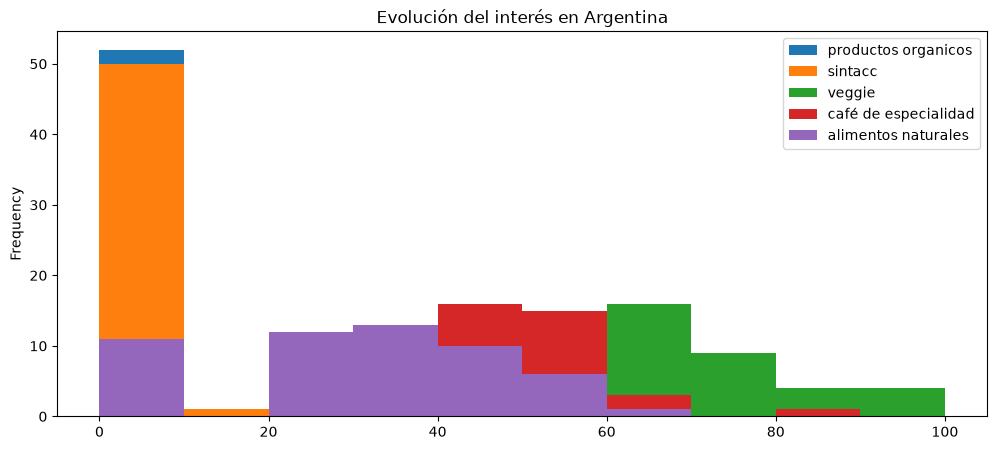

In [11]:
from pytrends.request import TrendReq

pytrends = TrendReq(hl="es-AR", tz=180)


conceptos = ["productos organicos", "sintacc", "veggie", "café de especialidad", "alimentos naturales"]

pytrends.build_payload(
    kw_list=conceptos,
    timeframe="today 12-m",   # últimos 5 años
    geo="AR",                # Argentina
)

df = pytrends.interest_over_time()
print(df.head())
df = df.drop(columns="isPartial")

df.plot(kind="hist", figsize=(12, 5), title="Evolución del interés en Argentina")